In [1]:
# imports and settings
import os, sys, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 140)

# colours and plot settings so all my charts look the same
NAVY, RED, GREY = "#1E2761", "#C0392B", "#7F8C8D"
CLASS_PALETTE = {0: NAVY, 1: RED}
CLASS_LABELS = {0: "Normal (0)", 1: "Needs maintenance (1)"}
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "axes.labelsize": 10})
FIG_DIR = "reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)
def save(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight")

# small helper to print which step is running, with the time
def log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)

In [2]:
# clean up results from earlier runs so everything starts fresh
# (otherwise mlflow keeps adding the same runs again every time the notebook is run)
import shutil
log("starting: clean up of old outputs")
for p in ["mlflow.db", "mlruns", "artifacts", "models", "data/processed", "data/registry.json"]:
    if os.path.isdir(p):
        shutil.rmtree(p)
    elif os.path.exists(p):
        os.remove(p)
log("finished: old outputs removed")

[19:06:56] starting: clean up of old outputs
[19:06:56] finished: old outputs removed


## 1. Data Registration
The csv is in the `data/` folder. Before using it, I check that it is what I expect:
- all 7 columns are there and there are no extra ones
- all values are numbers and in a sensible range
- the target (Engine Condition) only has 0 and 1
- there are enough rows

It also counts nulls and duplicates, prints a summary and saves `data/registry.json` with a hash of the file, so I can tell later if the data changed. If a check fails, it stops with an error.

In [3]:
# Step 1.1 - code to check (register) the dataset before using it
import hashlib, json
from datetime import datetime, timezone
from pathlib import Path

DATA_PATH = Path("data/engine_data.csv")
REGISTRY_PATH = Path("data/registry.json")

# columns I expect, with a min and max value that makes sense for each sensor
# (kept the limits wide so only clearly wrong values like negatives get caught)
EXPECTED_COLUMNS = {
    "Engine rpm":       (0, 5000),
    "Lub oil pressure": (0, 15),
    "Fuel pressure":    (0, 40),
    "Coolant pressure": (0, 15),
    "lub oil temp":     (0, 200),
    "Coolant temp":     (0, 250),
    "Engine Condition": (0, 1),
}
RAW_TARGET = "Engine Condition"


def sha256(path):
    # sha256 hash of the file - if the csv changes, this value changes
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def register_data(path=DATA_PATH, registry_path=REGISTRY_PATH):
    # runs all the checks, prints a small report and saves registry.json
    if not path.exists():
        raise FileNotFoundError(f"Dataset not found at {path}")
    data = pd.read_csv(path)
    checks = []

    # check 1 - are all the columns there?
    missing = [c for c in EXPECTED_COLUMNS if c not in data.columns]
    extra = [c for c in data.columns if c not in EXPECTED_COLUMNS]
    checks.append(("All expected columns present", not missing, f"missing={missing}"))
    checks.append(("No unexpected columns", not extra, f"extra={extra}"))
    if missing:
        raise ValueError(f"Registration failed: missing columns {missing}")

    # check 2 - numbers only, values in range, target is 0/1, enough rows
    non_numeric = [c for c in EXPECTED_COLUMNS if not pd.api.types.is_numeric_dtype(data[c])]
    checks.append(("All columns numeric", not non_numeric, f"non_numeric={non_numeric}"))
    out_of_range = {c: int(((data[c] < lo) | (data[c] > hi)).sum()) for c, (lo, hi) in EXPECTED_COLUMNS.items()}
    out_of_range = {c: n for c, n in out_of_range.items() if n}
    checks.append(("Values within plausible bounds", not out_of_range, f"{out_of_range}"))
    checks.append(("Target is binary {0,1}", set(data[RAW_TARGET].unique()) <= {0, 1},
                   f"values={sorted(data[RAW_TARGET].unique())}"))
    checks.append(("Minimum row count (>= 1,000)", len(data) >= 1000, f"rows={len(data)}"))

    # nulls and duplicates - just counting here, cleaning is done later in data prep
    n_null = int(data.isna().sum().sum())
    n_dup = int(data.duplicated().sum())

    print("=" * 64)
    print("DATASET REGISTRATION REPORT")
    print("=" * 64)
    print(f"File           : {path.name}")
    print(f"Rows x Columns : {data.shape[0]:,} x {data.shape[1]}")
    print(f"Null values    : {n_null}")
    print(f"Duplicate rows : {n_dup}")
    print("Class balance  : " + ", ".join(
        f"{k}={v:.2%}" for k, v in data[RAW_TARGET].value_counts(normalize=True).sort_index().items()))
    print("-" * 64)
    for name, ok, detail in checks:
        print(f"[{'PASS' if ok else 'FAIL'}] {name}" + ("" if ok else f"  -> {detail}"))
    print("-" * 64)
    print(data.describe().T[["mean", "std", "min", "50%", "max"]].round(2).to_string())

    passed = all(ok for _, ok, _ in checks)
    registry = {
        "dataset": path.name,
        "registered_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "sha256": sha256(path),
        "rows": int(data.shape[0]), "columns": list(data.columns),
        "nulls": n_null, "duplicates": n_dup,
        "target_distribution": {str(k): int(v) for k, v in data[RAW_TARGET].value_counts().sort_index().items()},
        "validation_passed": passed,
    }
    registry_path.write_text(json.dumps(registry, indent=2))
    print("-" * 64)
    print(f"Registry written to {registry_path}  |  status: {'VALID' if passed else 'INVALID'}")
    if not passed:
        raise ValueError("Registration failed: see the FAIL lines above")
    return registry

print(f"Registration code ready: {len(EXPECTED_COLUMNS)} expected columns, dataset at {DATA_PATH}")

Registration code ready: 7 expected columns, dataset at data/engine_data.csv


In [4]:
# Step 1.2 - run the check on engine_data.csv
log("starting: data registration")
registry = register_data()
log("finished: data registration")

[19:06:56] starting: data registration
DATASET REGISTRATION REPORT
File           : engine_data.csv
Rows x Columns : 19,535 x 7
Null values    : 0
Duplicate rows : 0
Class balance  : 0=36.95%, 1=63.05%
----------------------------------------------------------------
[PASS] All expected columns present
[PASS] No unexpected columns
[PASS] All columns numeric
[PASS] Values within plausible bounds
[PASS] Target is binary {0,1}
[PASS] Minimum row count (>= 1,000)
----------------------------------------------------------------
                   mean    std   min    50%      max
Engine rpm       791.24 267.61 61.00 746.00 2,239.00
Lub oil pressure   3.30   1.02  0.00   3.16     7.27
Fuel pressure      6.66   2.76  0.00   6.20    21.14
Coolant pressure   2.34   1.04  0.00   2.17     7.48
lub oil temp      77.64   3.11 71.32  76.82    89.58
Coolant temp      78.43   6.21 61.67  78.35   195.53
Engine Condition   0.63   0.48  0.00   1.00     1.00
------------------------------------------------

In [5]:
# Step 1.3 - print the registry.json file that got saved
print(json.dumps(json.load(open(REGISTRY_PATH)), indent=2))

{
  "dataset": "engine_data.csv",
  "registered_at_utc": "2026-10-18T13:36:56+00:00",
  "sha256": "616c7b985ec00e299061f02b11fd866f8eca16b5e8d15d4a61a5fbfd116b8045",
  "rows": 19535,
  "columns": [
    "Engine rpm",
    "Lub oil pressure",
    "Fuel pressure",
    "Coolant pressure",
    "lub oil temp",
    "Coolant temp",
    "Engine Condition"
  ],
  "nulls": 0,
  "duplicates": 0,
  "target_distribution": {
    "0": 7218,
    "1": 12317
  },
  "validation_passed": true
}


## 2. Exploratory Data Analysis
### 2.1 Data background
19,535 readings from 6 engine sensors (rpm, 3 pressures, 2 temperatures). The target `Engine Condition` is 1 if the engine needs maintenance and 0 if it is normal. The data has both small engines (like generators) and bigger car engines, so the ranges are quite wide.

In [6]:
# load the data for EDA
df = pd.read_csv("data/engine_data.csv")
SENSORS = [c for c in df.columns if c != "Engine Condition"]
TARGET = "Engine Condition"
UNITS = {"Engine rpm": "RPM", "Lub oil pressure": "bar", "Fuel pressure": "bar",
         "Coolant pressure": "bar", "lub oil temp": "°C", "Coolant temp": "°C"}
print(df.shape)
df.head()

(19535, 7)


,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
0,700,2.49,11.79,3.18,84.14,81.63,1
1,876,2.94,16.19,2.46,77.64,82.45,0
2,520,2.96,6.55,1.06,77.75,79.65,1
3,473,3.71,19.51,3.73,74.13,71.77,1
4,619,5.67,15.74,2.05,78.40,87.00,0


### 2.2 Data overview

In [7]:
# column types and missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19535 entries, 0 to 19534
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Engine rpm        19535 non-null  int64  
 1   Lub oil pressure  19535 non-null  float64
 2   Fuel pressure     19535 non-null  float64
 3   Coolant pressure  19535 non-null  float64
 4   lub oil temp      19535 non-null  float64
 5   Coolant temp      19535 non-null  float64
 6   Engine Condition  19535 non-null  int64  
dtypes: float64(5), int64(2)
memory usage: 1.0 MB


In [8]:
# summary stats + skew and kurtosis for each column
overview = df.describe().T
overview["skew"] = df.skew()
overview["kurtosis"] = df.kurtosis()
overview["nulls"] = df.isna().sum()
overview.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,nulls
Engine rpm,"19,535.00",791.24,267.61,61.00,593.00,746.00,934.00,"2,239.00",0.93,0.94,0
Lub oil pressure,"19,535.00",3.30,1.02,0.00,2.52,3.16,4.06,7.27,0.20,-0.26,0
Fuel pressure,"19,535.00",6.66,2.76,0.00,4.92,6.20,7.74,21.14,1.22,2.45,0
Coolant pressure,"19,535.00",2.34,1.04,0.00,1.60,2.17,2.85,7.48,1.31,2.56,0
lub oil temp,"19,535.00",77.64,3.11,71.32,75.73,76.82,78.07,89.58,1.50,1.75,0
Coolant temp,"19,535.00",78.43,6.21,61.67,73.90,78.35,82.92,195.53,0.40,5.88,0
Engine Condition,"19,535.00",0.63,0.48,0.00,0.00,1.00,1.00,1.00,-0.54,-1.71,0


In [9]:
# any duplicate rows? and how many unique values per column
print("Duplicate rows:", df.duplicated().sum())
print("Unique values per column:")
print(df.nunique())

Duplicate rows: 0
Unique values per column:
Engine rpm           1379
Lub oil pressure    19534
Fuel pressure       19531
Coolant pressure    19534
lub oil temp        19530
Coolant temp        19532
Engine Condition        2
dtype: int64


### 2.3 Univariate analysis

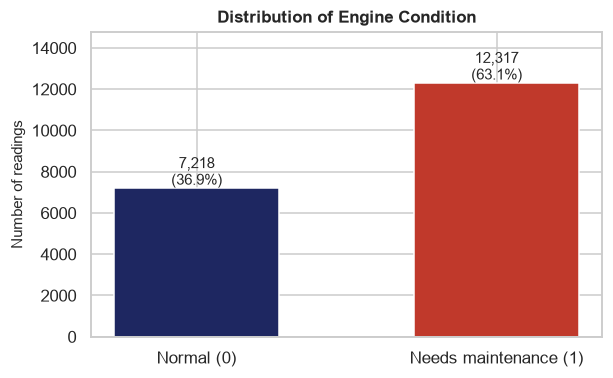

In [10]:
# how many engines are normal vs need maintenance
fig, ax = plt.subplots(figsize=(6, 3.6))
counts = df[TARGET].value_counts().sort_index()
bars = ax.bar([CLASS_LABELS[i] for i in counts.index], counts.values, color=[NAVY, RED], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 150, f"{v:,}\n({v/len(df):.1%})", ha="center", fontsize=10)
ax.set_ylabel("Number of readings"); ax.set_ylim(0, counts.max()*1.2)
ax.set_title("Distribution of Engine Condition")
save(fig, "fig01_target_distribution"); plt.show()

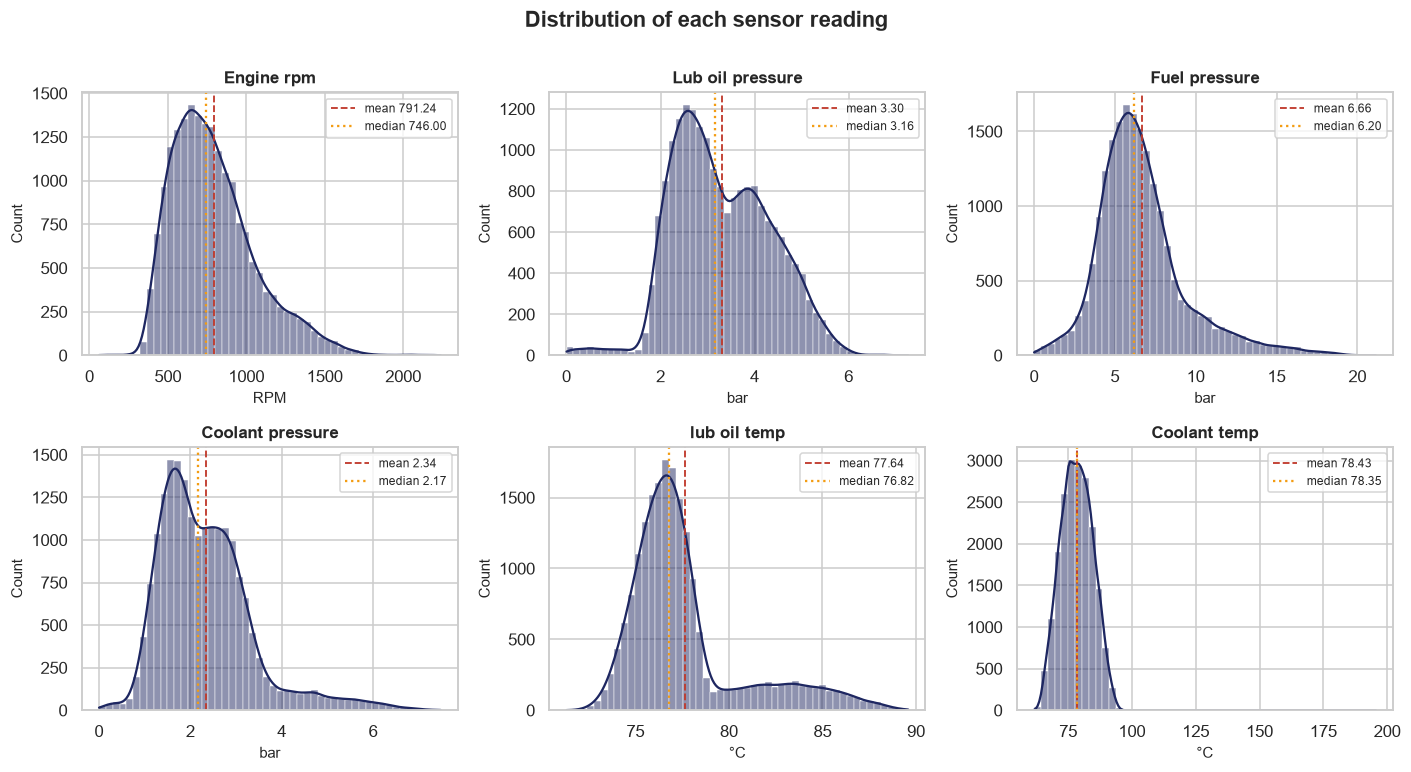

In [11]:
# histogram for each sensor (red = mean, orange = median)
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.flat, SENSORS):
    sns.histplot(df[c], bins=50, kde=True, color=NAVY, ax=ax, edgecolor="white", linewidth=0.3)
    ax.axvline(df[c].mean(), color=RED, ls="--", lw=1.2, label=f"mean {df[c].mean():.2f}")
    ax.axvline(df[c].median(), color="#F39C12", ls=":", lw=1.5, label=f"median {df[c].median():.2f}")
    ax.set_title(c); ax.set_xlabel(UNITS[c]); ax.set_ylabel("Count"); ax.legend(fontsize=8)
fig.suptitle("Distribution of each sensor reading", fontweight="bold", y=1.0)
fig.tight_layout(); save(fig, "fig02_histograms"); plt.show()

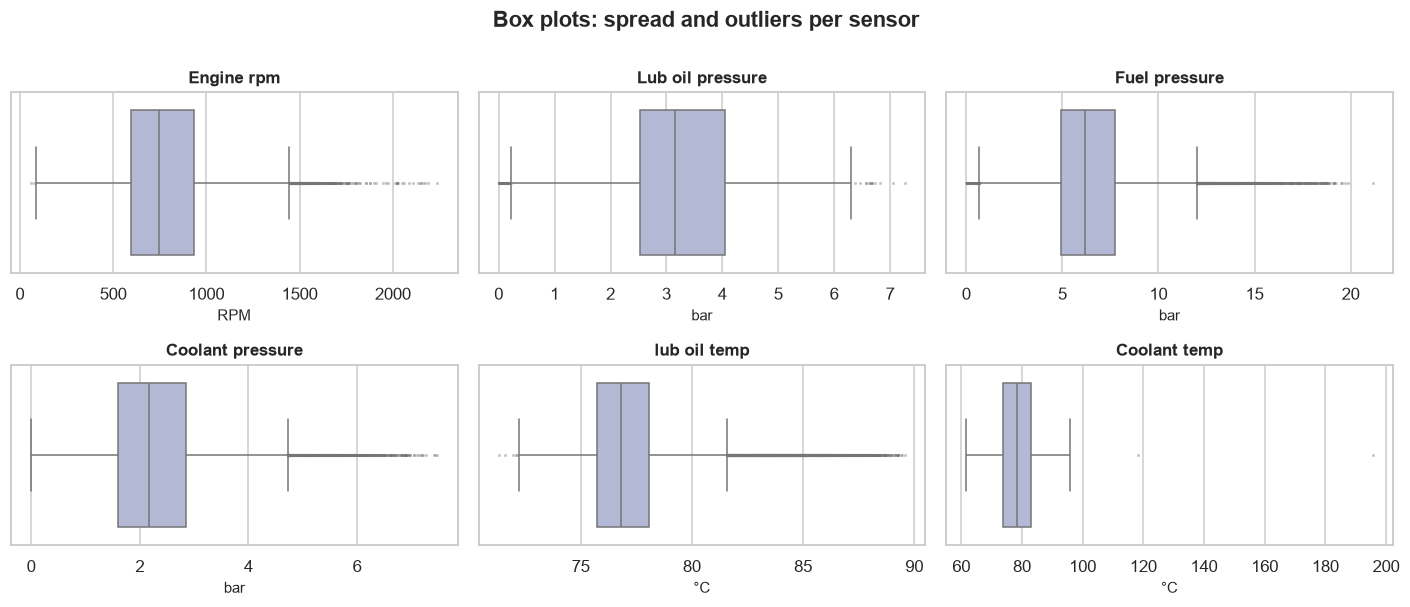

In [12]:
# box plots to see spread and outliers
fig, axes = plt.subplots(2, 3, figsize=(13, 5.5))
for ax, c in zip(axes.flat, SENSORS):
    sns.boxplot(x=df[c], color="#AEB6D9", ax=ax, flierprops=dict(marker=".", markersize=2, alpha=0.4))
    ax.set_title(c); ax.set_xlabel(UNITS[c])
fig.suptitle("Box plots: spread and outliers per sensor", fontweight="bold", y=1.0)
fig.tight_layout(); save(fig, "fig03_boxplots"); plt.show()

In [13]:
# outliers using the IQR rule (outside 1.5 x IQR)
# also checking how many of these outlier engines are faulty
rows = []
for c in SENSORS:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    m = (df[c] < lo) | (df[c] > hi)
    rows.append({"sensor": c, "lower_fence": lo, "upper_fence": hi, "outliers": int(m.sum()),
                 "outlier_pct": 100*m.mean(), "fault_rate_in_outliers_pct": 100*df.loc[m, TARGET].mean()})
outlier_tbl = pd.DataFrame(rows).set_index("sensor")
print(f"Overall fault rate: {100*df[TARGET].mean():.2f}%")
outlier_tbl.round(2)

Overall fault rate: 63.05%


,lower_fence,upper_fence,outliers,outlier_pct,fault_rate_in_outliers_pct
sensor,,,,,
Engine rpm,81.50,"1,445.50",464,2.38,37.50
Lub oil pressure,0.21,6.36,66,0.34,65.15
Fuel pressure,0.67,11.99,1135,5.81,68.81
Coolant pressure,-0.27,4.72,785,4.02,56.31
lub oil temp,72.21,81.59,2617,13.40,56.13
Coolant temp,60.37,96.45,2,0.01,50.00


### 2.4 Bivariate analysis (each sensor vs Engine Condition)

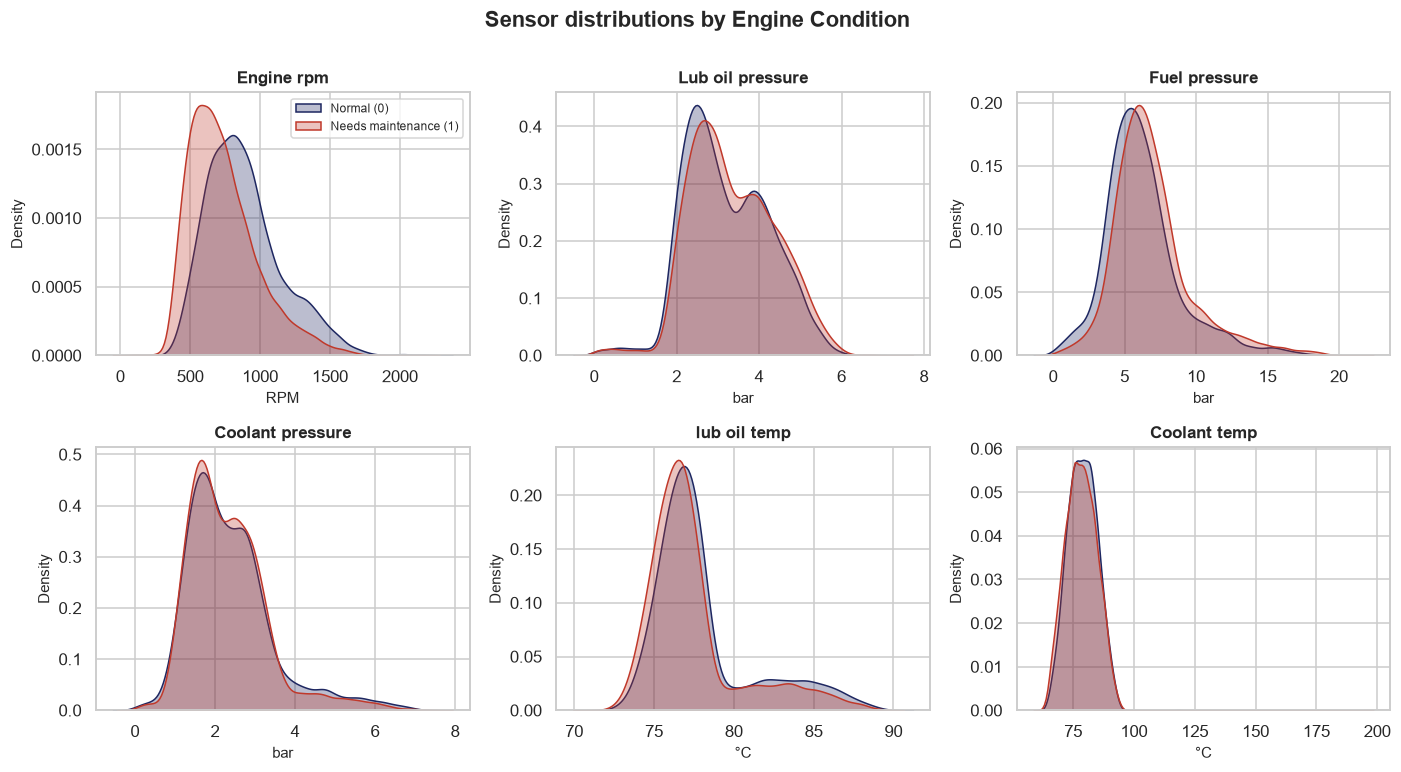

In [14]:
# density plot of each sensor for normal vs faulty
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.flat, SENSORS):
    for k in [0, 1]:
        sns.kdeplot(df.loc[df[TARGET]==k, c], ax=ax, fill=True, alpha=0.3, color=CLASS_PALETTE[k],
                    label=CLASS_LABELS[k], common_norm=False)
    ax.set_title(c); ax.set_xlabel(UNITS[c]); ax.set_ylabel("Density")
axes.flat[0].legend(fontsize=8)
fig.suptitle("Sensor distributions by Engine Condition", fontweight="bold", y=1.0)
fig.tight_layout(); save(fig, "fig04_kde_by_class"); plt.show()

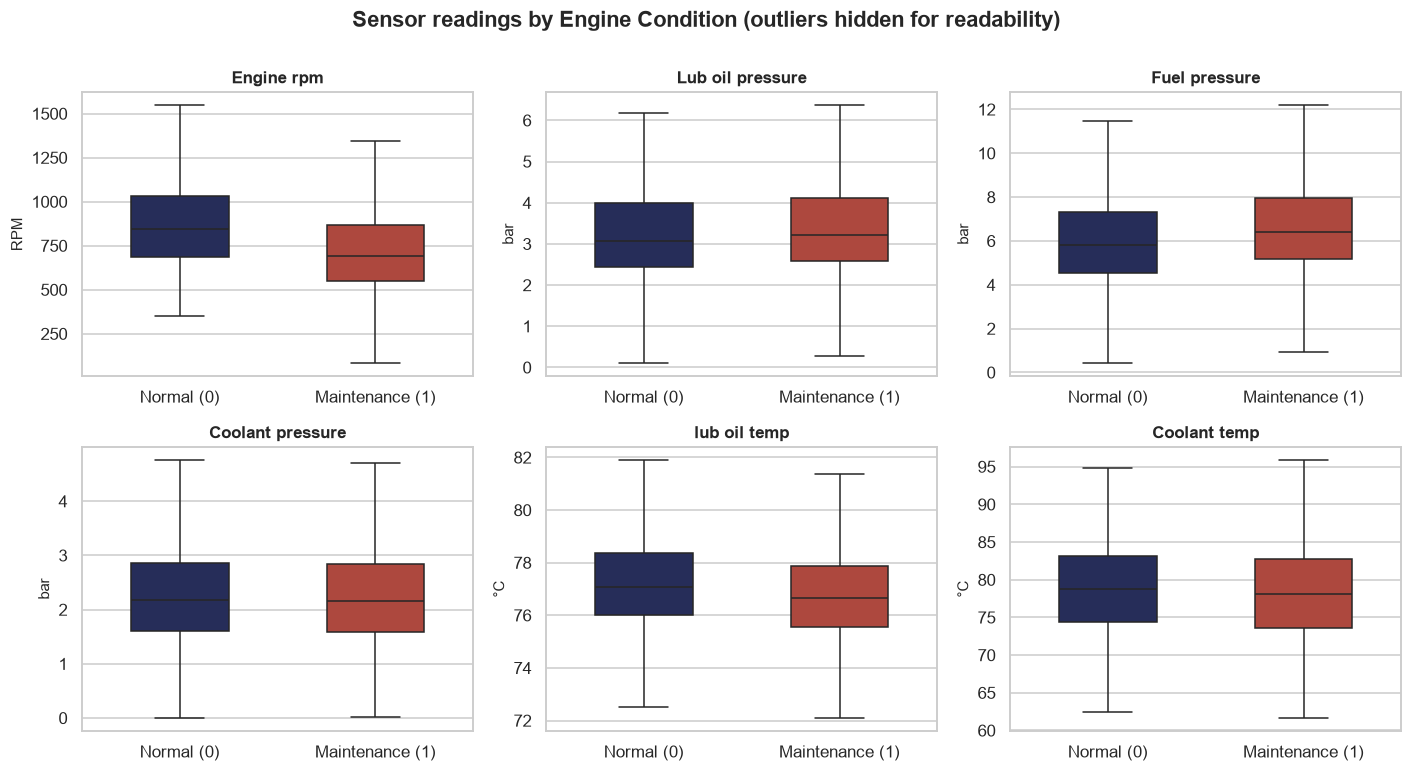

In [15]:
# box plots of each sensor for normal vs faulty
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.flat, SENSORS):
    sns.boxplot(data=df, x=TARGET, y=c, hue=TARGET, palette=CLASS_PALETTE, legend=False, ax=ax, showfliers=False, width=0.5)
    ax.set_xticklabels(["Normal (0)", "Maintenance (1)"]); ax.set_xlabel(""); ax.set_ylabel(UNITS[c]); ax.set_title(c)
fig.suptitle("Sensor readings by Engine Condition (outliers hidden for readability)", fontweight="bold", y=1.0)
fig.tight_layout(); save(fig, "fig05_box_by_class"); plt.show()

In [16]:
# compare normal vs faulty engines for each sensor - medians, correlation and mann-whitney test
rows = []
for c in SENSORS:
    a, b = df.loc[df[TARGET]==0, c], df.loc[df[TARGET]==1, c]
    u, p = stats.mannwhitneyu(a, b)
    r_pb, _ = stats.pointbiserialr(df[TARGET], df[c])
    rows.append({"sensor": c, "median_normal": a.median(), "median_faulty": b.median(),
                 "median_diff_pct": 100*(b.median()-a.median())/a.median(),
                 "point_biserial_r": r_pb, "mann_whitney_p": p})
biv = pd.DataFrame(rows).set_index("sensor").sort_values("point_biserial_r", key=abs, ascending=False)
biv.style.format({"median_normal": "{:.2f}", "median_faulty": "{:.2f}", "median_diff_pct": "{:.2f}",
                  "point_biserial_r": "{:.3f}", "mann_whitney_p": "{:.2e}"})

,median_normal,median_faulty,median_diff_pct,point_biserial_r,mann_whitney_p
sensor,,,,,
Engine rpm,843.00,690.00,-18.15,-0.268,0.00e+00
Fuel pressure,5.82,6.42,10.25,0.116,8.11e-78
lub oil temp,77.09,76.66,-0.56,-0.094,1.21e-58
Lub oil pressure,3.07,3.21,4.80,0.061,1.53e-18
Coolant temp,78.77,78.10,-0.85,-0.046,8.99e-11
Coolant pressure,2.18,2.16,-1.09,-0.024,8.02e-02


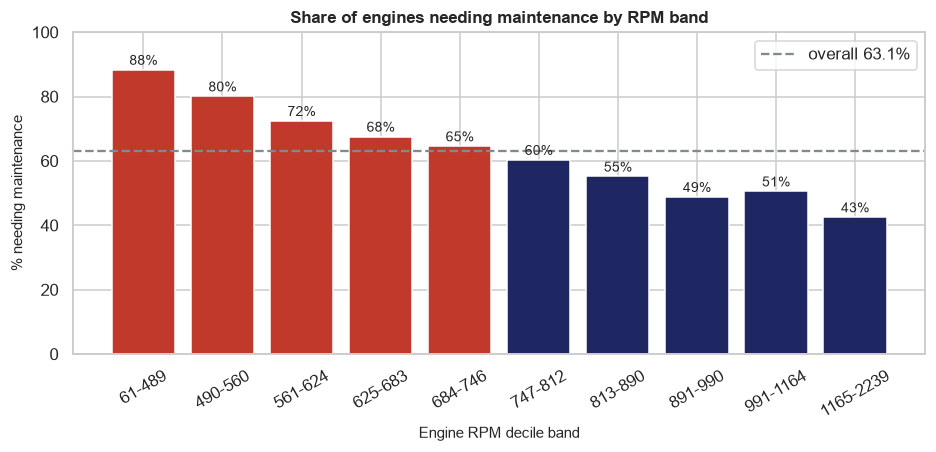

,fault_rate_pct
61-489,88.33
490-560,80.07
561-624,72.45
625-683,67.57
684-746,64.57
747-812,60.34
813-890,55.15
891-990,48.83
991-1164,50.54
1165-2239,42.52


In [17]:
# rpm looked like the strongest one, so split rpm into 10 equal groups and check % faulty in each
df["_rpm_decile"] = pd.qcut(df["Engine rpm"], 10)
rate = df.groupby("_rpm_decile", observed=True)[TARGET].agg(["mean", "size"])
rate.index = [f"{int(i.left)+1}-{int(i.right)}" for i in rate.index]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(rate.index, 100*rate["mean"], color=[RED if v > df[TARGET].mean() else NAVY for v in rate["mean"]])
ax.axhline(100*df[TARGET].mean(), color=GREY, ls="--", label=f"overall {100*df[TARGET].mean():.1f}%")
for i, v in enumerate(rate["mean"]):
    ax.text(i, 100*v + 1.5, f"{100*v:.0f}%", ha="center", fontsize=9)
ax.set_ylabel("% needing maintenance"); ax.set_xlabel("Engine RPM decile band"); ax.set_ylim(0, 100)
ax.set_title("Share of engines needing maintenance by RPM band"); ax.legend()
plt.xticks(rotation=30); save(fig, "fig06_fault_rate_by_rpm"); plt.show()
df.drop(columns="_rpm_decile", inplace=True)
(100*rate["mean"]).round(2).to_frame("fault_rate_pct")

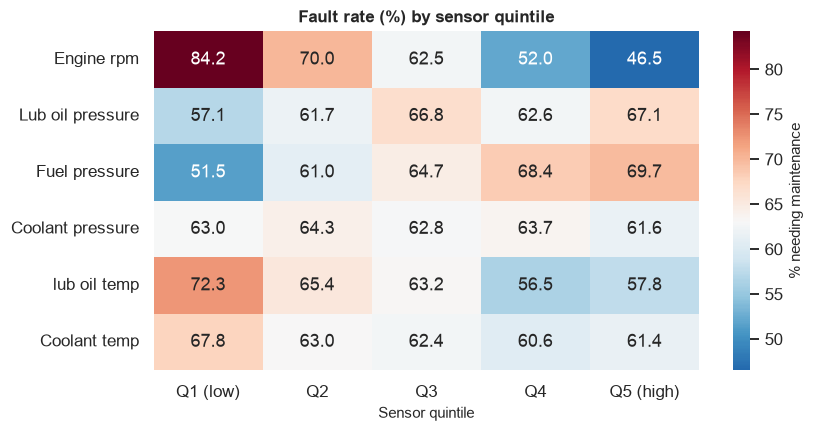

,Q1 (low),Q2,Q3,Q4,Q5 (high)
Engine rpm,84.21,70.01,62.46,51.98,46.52
Lub oil pressure,57.05,61.74,66.83,62.55,67.08
Fuel pressure,51.50,60.97,64.68,68.36,69.75
Coolant pressure,62.96,64.27,62.76,63.71,61.56
lub oil temp,72.31,65.42,63.25,56.49,57.79
Coolant temp,67.83,63.02,62.43,60.58,61.40


In [18]:
# same idea for all sensors - split each into 5 groups and show % faulty as a heatmap
fr = {}
for c in SENSORS:
    q = pd.qcut(df[c], 5, labels=["Q1 (low)", "Q2", "Q3", "Q4", "Q5 (high)"])
    fr[c] = df.groupby(q, observed=True)[TARGET].mean()*100
fr = pd.DataFrame(fr).T
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(fr, annot=True, fmt=".1f", cmap="RdBu_r", center=100*df[TARGET].mean(), ax=ax,
            cbar_kws={"label": "% needing maintenance"})
ax.set_title("Fault rate (%) by sensor quintile"); ax.set_xlabel("Sensor quintile"); ax.set_ylabel("")
save(fig, "fig07_fault_rate_quintiles"); plt.show()
fr.round(2)

### 2.5 Multivariate analysis

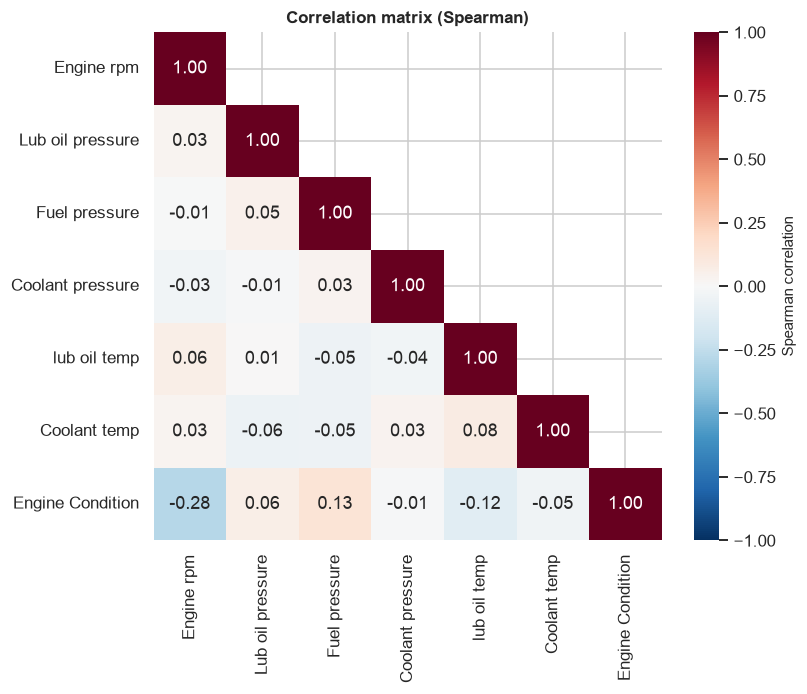

In [19]:
# correlation between all columns (spearman since data is skewed)
fig, ax = plt.subplots(figsize=(7.5, 6))
corr = df.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, square=True,
            cbar_kws={"label": "Spearman correlation"})
ax.set_title("Correlation matrix (Spearman)")
save(fig, "fig08_correlation"); plt.show()

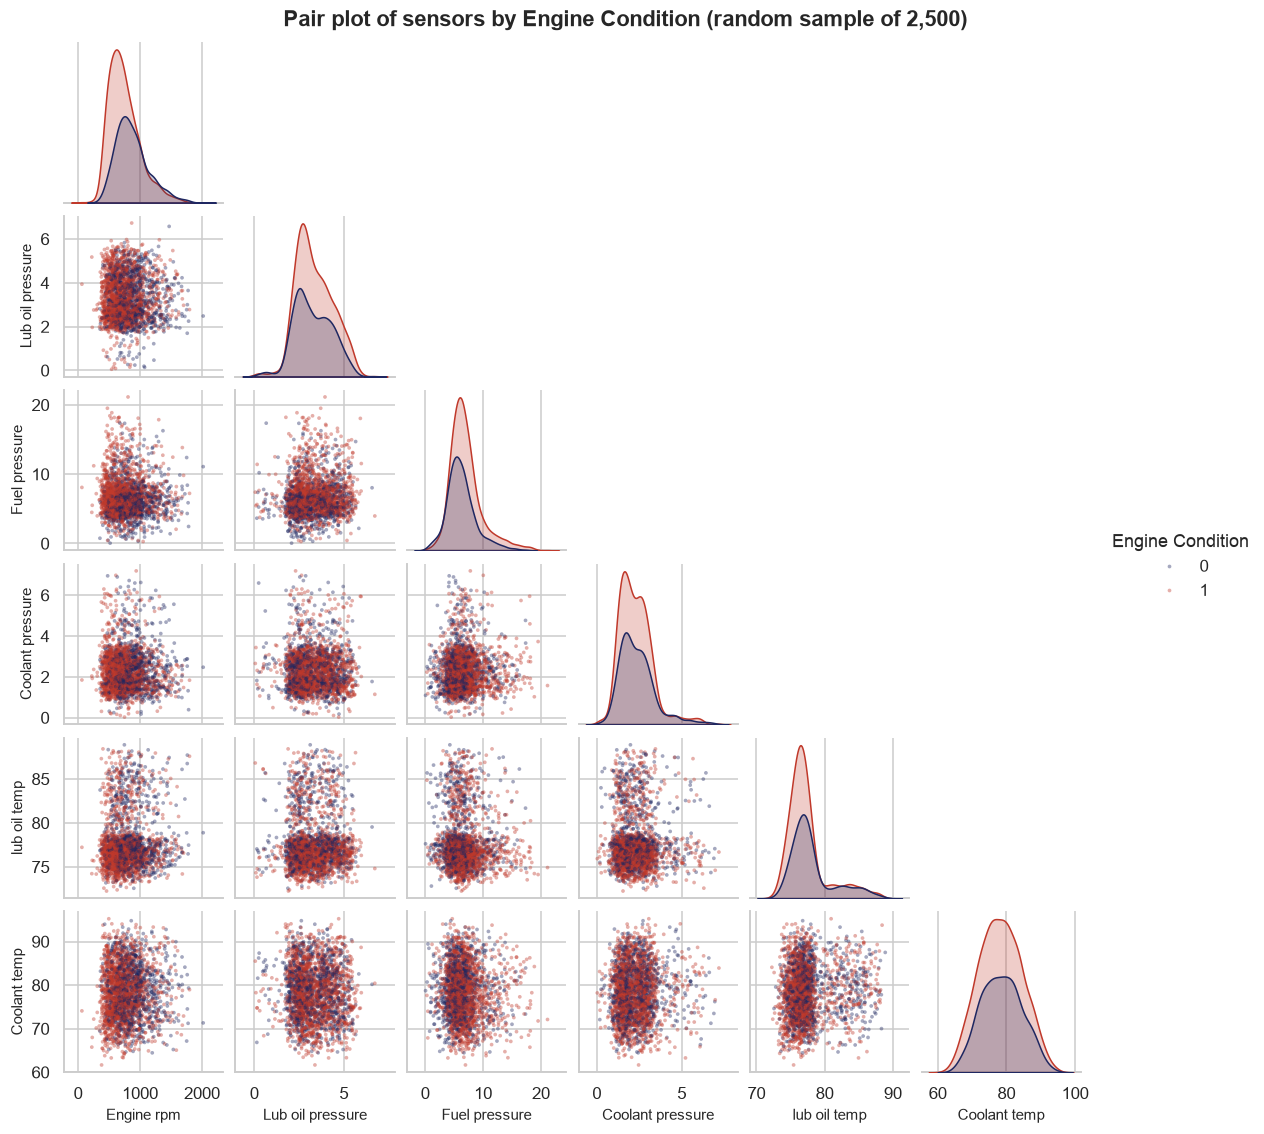

In [20]:
# pair plot on a sample of 2500 rows (full data is too slow and messy)
sample = df.sample(2500, random_state=42)
g = sns.pairplot(sample, hue=TARGET, palette=CLASS_PALETTE, plot_kws=dict(s=6, alpha=0.4, linewidth=0),
                 diag_kind="kde", corner=True, height=1.7)
g._legend.set_title("Engine Condition")
g.figure.suptitle("Pair plot of sensors by Engine Condition (random sample of 2,500)", fontweight="bold", y=1.01)
g.figure.savefig(f"{FIG_DIR}/fig09_pairplot.png", bbox_inches="tight", dpi=130); plt.show()

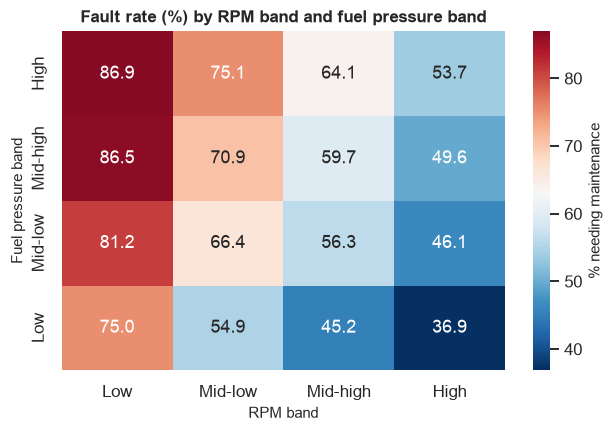

RPM band,Low,Mid-low,Mid-high,High
Fuel pressure band,,,,
Low,75.02,54.93,45.24,36.86
Mid-low,81.21,66.42,56.33,46.11
Mid-high,86.46,70.86,59.69,49.63
High,86.92,75.08,64.08,53.74


In [21]:
# checking rpm and fuel pressure together - % faulty for each combination
tmp = df.copy()
tmp["RPM band"] = pd.qcut(tmp["Engine rpm"], 4, labels=["Low", "Mid-low", "Mid-high", "High"])
tmp["Fuel pressure band"] = pd.qcut(tmp["Fuel pressure"], 4, labels=["Low", "Mid-low", "Mid-high", "High"])
pv = tmp.pivot_table(index="Fuel pressure band", columns="RPM band", values=TARGET, aggfunc="mean", observed=True)*100
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.heatmap(pv, annot=True, fmt=".1f", cmap="RdBu_r", center=100*df[TARGET].mean(), ax=ax,
            cbar_kws={"label": "% needing maintenance"})
ax.set_title("Fault rate (%) by RPM band and fuel pressure band"); ax.invert_yaxis()
save(fig, "fig10_rpm_fuel_interaction"); plt.show()
pv.round(2)

Explained variance ratio per component: [0.19  0.177 0.171 0.157 0.156 0.149]


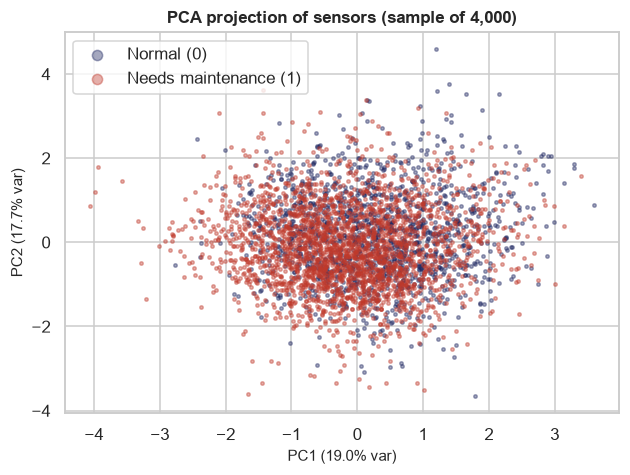

In [22]:
# PCA to see if the two classes separate (scaled the sensors first)
# only for understanding the data, not used in the models
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
Z = StandardScaler().fit_transform(df[SENSORS])
pca = PCA().fit(Z)
print("Explained variance ratio per component:", np.round(pca.explained_variance_ratio_, 3))
pc = pca.transform(Z)[:, :2]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
idx = np.random.RandomState(0).choice(len(df), 4000, replace=False)
for k in [0, 1]:
    m = df[TARGET].values[idx] == k
    ax.scatter(pc[idx][m, 0], pc[idx][m, 1], s=5, alpha=0.4, color=CLASS_PALETTE[k], label=CLASS_LABELS[k])
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} var)"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} var)")
ax.set_title("PCA projection of sensors (sample of 4,000)"); ax.legend(markerscale=3)
save(fig, "fig11_pca"); plt.show()

### 2.6 What I found in EDA
* **Data is clean** - no missing values, no duplicates, and values are in normal ranges, so nothing to fill in.
* **63% of engines are faulty** - so a model that always says "faulty" already gets 63% accuracy and F1 of 0.77. That is why I use ROC-AUC to compare models and always check against this baseline.
* **RPM matters the most** - in the lowest rpm group 88% need maintenance, in the highest only 43%. Low rpm usually means the engine is struggling.
* **Fuel pressure and lube oil pressure help a bit** - faulty engines have about 10% higher fuel pressure and 5% higher oil pressure. Temperatures are slightly lower for faulty ones.
* **Sensors are not correlated with each other** (all below 0.1) so no sensor is repeating another. But normal and faulty engines overlap a lot in every plot and in PCA, so I don't expect very high accuracy. Tree models should work better than linear ones here.
* **Outliers are useful** - outliers in fuel pressure (69% faulty) and lube oil pressure (65% faulty) are more often faulty than normal engines, so I am keeping them.

## 3. Data Preparation
Steps in the code below:
1. load the csv straight from the `data/` folder
2. rename the columns (lowercase, no spaces)
3. remove duplicates and missing values
4. remove columns we don't need (constant or id-type columns) - there aren't any, but the code checks
5. remove impossible values (rpm 0 or negative numbers)
6. keep the outliers (trees can handle them and EDA showed they are useful)
7. split 80/20 with stratify so train and test have the same % faulty, and save to `data/processed/`

This folder is passed to the training step as the artifact `train-test-data`.

In [23]:
# Step 3.1 - data preparation: cleaning + train/test split
from sklearn.model_selection import train_test_split

RAW_PATH = Path("data/engine_data.csv")      # read straight from the data folder
PROCESSED_DIR = Path("data/processed")       # train and test files are saved here
TEST_SIZE, SEED = 0.20, 42
CLEAN_TARGET = "engine_condition"
RENAME = {"Engine rpm": "engine_rpm", "Lub oil pressure": "lub_oil_pressure",
          "Fuel pressure": "fuel_pressure", "Coolant pressure": "coolant_pressure",
          "lub oil temp": "lub_oil_temp", "Coolant temp": "coolant_temp",
          "Engine Condition": CLEAN_TARGET}


def prepare_data(raw_path=RAW_PATH, out_dir=PROCESSED_DIR):
    # cleans the data, splits it 80/20 and saves train.csv and test.csv
    data = pd.read_csv(raw_path)
    log = {"raw_rows": len(data)}

    # 1. rename columns (no spaces, all lowercase)
    data = data.rename(columns=RENAME)

    # 2. drop duplicates and rows with missing values
    log["duplicates_removed"] = int(data.duplicated().sum())
    data = data.drop_duplicates()
    log["null_rows_removed"] = int(data.isna().any(axis=1).sum())
    data = data.dropna()

    # 3. drop columns we don't need (constant columns, id columns, anything extra)
    constant = [c for c in data.columns if data[c].nunique() <= 1]
    id_like = [c for c in data.columns if c != CLEAN_TARGET and data[c].nunique() == len(data)
               and pd.api.types.is_integer_dtype(data[c])]
    unknown = [c for c in data.columns if c not in RENAME.values()]
    drop_cols = sorted(set(constant + id_like + unknown))
    data = data.drop(columns=drop_cols)
    log["columns_dropped"] = drop_cols

    # 4. drop impossible rows (rpm 0 or negative values)
    features = [c for c in data.columns if c != CLEAN_TARGET]
    impossible = (data["engine_rpm"] <= 0) | (data[features] < 0).any(axis=1)
    log["impossible_rows_removed"] = int(impossible.sum())
    data = data[~impossible]

    # 5. count outliers but don't remove them - EDA showed they are often faulty engines
    q1, q3 = data[features].quantile(0.25), data[features].quantile(0.75)
    iqr = q3 - q1
    out_mask = (data[features] < q1 - 1.5 * iqr) | (data[features] > q3 + 1.5 * iqr)
    log["rows_with_any_iqr_outlier_kept"] = int(out_mask.any(axis=1).sum())

    # 6. split 80/20 (stratify keeps the same % faulty in both) and save
    X, y = data[features], data[CLEAN_TARGET].astype(int)
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
    out_dir.mkdir(parents=True, exist_ok=True)
    pd.concat([X_tr, y_tr], axis=1).to_csv(out_dir / "train.csv", index=False)
    pd.concat([X_te, y_te], axis=1).to_csv(out_dir / "test.csv", index=False)

    log.update({"clean_rows": len(data), "features": features, "target": CLEAN_TARGET,
                "train_rows": len(X_tr), "test_rows": len(X_te),
                "train_positive_rate": round(float(y_tr.mean()), 4),
                "test_positive_rate": round(float(y_te.mean()), 4),
                "test_size": TEST_SIZE, "random_state": SEED})
    (out_dir / "prep_summary.json").write_text(json.dumps(log, indent=2))
    print(json.dumps(log, indent=2))
    print(f"Saved train/test splits to {out_dir}/")
    return log

print(f"Preparation code ready: source {RAW_PATH}, output {PROCESSED_DIR}/, test size {TEST_SIZE:.0%}, seed {SEED}")

Preparation code ready: source data/engine_data.csv, output data/processed/, test size 20%, seed 42


In [24]:
# Step 3.2 - run the data prep
log("starting: data preparation")
prep_log = prepare_data()
log("finished: data preparation")

[19:07:00] starting: data preparation
{
  "raw_rows": 19535,
  "duplicates_removed": 0,
  "null_rows_removed": 0,
  "columns_dropped": [],
  "impossible_rows_removed": 0,
  "rows_with_any_iqr_outlier_kept": 4636,
  "clean_rows": 19535,
  "features": [
    "engine_rpm",
    "lub_oil_pressure",
    "fuel_pressure",
    "coolant_pressure",
    "lub_oil_temp",
    "coolant_temp"
  ],
  "target": "engine_condition",
  "train_rows": 15628,
  "test_rows": 3907,
  "train_positive_rate": 0.6305,
  "test_positive_rate": 0.6304,
  "test_size": 0.2,
  "random_state": 42
}
Saved train/test splits to data/processed/
[19:07:00] finished: data preparation


In [25]:
# Step 3.3 - check the % faulty is the same in train and test
train = pd.read_csv(PROCESSED_DIR / "train.csv"); test = pd.read_csv(PROCESSED_DIR / "test.csv")
split_tbl = pd.DataFrame({
    "rows": [len(train), len(test)],
    "normal (0)": [(train.engine_condition==0).sum(), (test.engine_condition==0).sum()],
    "needs maintenance (1)": [(train.engine_condition==1).sum(), (test.engine_condition==1).sum()],
    "% needs maintenance": [100*train.engine_condition.mean(), 100*test.engine_condition.mean()]},
    index=["train", "test"])
split_tbl.round(2)

,rows,normal (0),needs maintenance (1),% needs maintenance
train,15628,5774,9854,63.05
test,3907,1444,2463,63.04


### 3.4 Passing the split to the next step (artifact)
In the pipeline, the data prep job uploads `data/processed/` as the artifact `train-test-data` and the training job downloads it. Each job runs on a new machine, so this is how the data gets from one job to the next.

Here I do the same thing by copying the split to `artifacts/train-test-data/`. The training code in Part 4 only reads from this folder.

In [26]:
# Step 3.5 - copy the split into artifacts/ for the training step
log("starting: copying the split to artifacts/")
import shutil
ARTIFACT_DIR = Path("artifacts/train-test-data")
shutil.rmtree(ARTIFACT_DIR, ignore_errors=True)
shutil.copytree(PROCESSED_DIR, ARTIFACT_DIR)
print("Artifact 'train-test-data' contents:", sorted(os.listdir(ARTIFACT_DIR)))
log("finished: copying the split to artifacts/")

[19:07:00] starting: copying the split to artifacts/
Artifact 'train-test-data' contents: ['prep_summary.json', 'test.csv', 'train.csv']
[19:07:00] finished: copying the split to artifacts/


## 4. Model Building with Experiment Tracking
I tried the 6 models from the rubric: Decision Tree, Bagging, Random Forest, AdaBoost, Gradient Boosting and XGBoost. I also added a dummy model that always predicts "faulty" as a baseline.

**Why ROC-AUC and not F1/accuracy?** 63% of engines are faulty, so just predicting "faulty" for everything gives accuracy 0.63, recall 1.00 and F1 0.77. If I tune on F1 the models start doing exactly that. ROC-AUC checks how well the model ranks faulty engines above normal ones, so it doesn't have this problem. I still report accuracy, precision, recall and F1 (at 0.5 cut-off).

**How:**
- RandomizedSearchCV with 20 random parameter combinations per model and 5-fold stratified CV (on train data only)
- every combination is logged in MLflow as a child run (parameters + CV scores)
- for each model, the parent run has the best parameters, test scores, confusion matrix numbers and the model
- best model is picked using CV ROC-AUC (not the test score) and saved to `models/best_model.joblib` with a metadata file

In [27]:
# Step 4.1 - training setup: mlflow, the 6 models and the parameters to try for each
import time
import joblib
import mlflow, mlflow.sklearn
from scipy.stats import randint, uniform, loguniform
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier,
                              GradientBoostingClassifier, RandomForestClassifier)
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

MODEL_DIR = Path("models")
N_ITER, CV_FOLDS = 20, 5
REFIT = "roc_auc"   # using roc_auc to pick the best - f1 is already 0.77 if we just say "faulty" for everything
EXPERIMENT = "engine-predictive-maintenance"
mlflow.set_tracking_uri(f"sqlite:///{os.path.abspath('mlflow.db')}")
mlflow.set_experiment(EXPERIMENT)
import logging
logging.getLogger("mlflow").setLevel(logging.ERROR)   # mlflow prints a lot of warnings, hiding them

# n_jobs=1 inside the models because the search below already runs in parallel
MODELS = {
    "DecisionTree": (DecisionTreeClassifier(random_state=SEED), {
        "max_depth": randint(2, 15), "min_samples_split": randint(2, 200),
        "min_samples_leaf": randint(1, 100), "criterion": ["gini", "entropy"],
        "class_weight": [None, "balanced"]}),
    "Bagging": (BaggingClassifier(estimator=DecisionTreeClassifier(), random_state=SEED, n_jobs=1), {
        "n_estimators": randint(50, 200), "max_samples": uniform(0.3, 0.7),
        "max_features": uniform(0.5, 0.5), "bootstrap": [True, False],
        "estimator__max_depth": randint(3, 12), "estimator__min_samples_leaf": randint(1, 50)}),
    "RandomForest": (RandomForestClassifier(random_state=SEED, n_jobs=1), {
        "n_estimators": randint(100, 300), "max_depth": randint(3, 16),
        "min_samples_leaf": randint(1, 60), "max_features": ["sqrt", "log2", None],
        "class_weight": [None, "balanced", "balanced_subsample"]}),
    "AdaBoost": (AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), random_state=SEED), {
        "n_estimators": randint(50, 300), "learning_rate": loguniform(0.01, 1.0),
        "estimator__max_depth": randint(1, 4)}),
    "GradientBoosting": (GradientBoostingClassifier(random_state=SEED), {
        "n_estimators": randint(100, 300), "learning_rate": loguniform(0.01, 0.3),
        "max_depth": randint(2, 6), "subsample": uniform(0.6, 0.4),
        "min_samples_leaf": randint(1, 80)}),
    "XGBoost": (XGBClassifier(random_state=SEED, n_jobs=1, eval_metric="logloss", tree_method="hist"), {
        "n_estimators": randint(100, 400), "learning_rate": loguniform(0.01, 0.3),
        "max_depth": randint(2, 8), "subsample": uniform(0.6, 0.4),
        "colsample_bytree": uniform(0.5, 0.5), "min_child_weight": randint(1, 20),
        "gamma": uniform(0, 5), "reg_lambda": loguniform(0.1, 10)}),
}
SCORING = {"roc_auc": "roc_auc", "f1": "f1", "recall": "recall", "precision": "precision", "accuracy": "accuracy"}


def evaluate(model, X, y):
    # get all the scores on the test set (roc_auc needs the probabilities)
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, proba)}, pred


def clean(v):
    # round long decimals before logging
    return round(float(v), 6) if isinstance(v, float) else v

print("MLflow experiment:", EXPERIMENT, "| algorithms:", list(MODELS))

2026/10/18 19:07:01 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/18 19:07:01 INFO mlflow.store.db.utils: Updating database tables
2026/10/18 19:07:01 INFO mlflow.tracking.fluent: Experiment with name 'engine-predictive-maintenance' does not exist. Creating a new experiment.


MLflow experiment: engine-predictive-maintenance | algorithms: ['DecisionTree', 'Bagging', 'RandomForest', 'AdaBoost', 'GradientBoosting', 'XGBoost']


In [28]:
# Step 4.2 - load train and test from the artifacts folder
train_art = pd.read_csv(ARTIFACT_DIR / "train.csv")
test_art = pd.read_csv(ARTIFACT_DIR / "test.csv")
X_tr, y_tr = train_art.drop(columns=CLEAN_TARGET), train_art[CLEAN_TARGET]
X_te, y_te = test_art.drop(columns=CLEAN_TARGET), test_art[CLEAN_TARGET]
print(f"Loaded artifact from {ARTIFACT_DIR}: train={X_tr.shape}, test={X_te.shape}")

Loaded artifact from artifacts/train-test-data: train=(15628, 6), test=(3907, 6)


In [29]:
# Step 4.3 - baseline model that always says 'faulty', to compare the real models against
log("starting: baseline model")
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
results, fitted = [], {}

dummy = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
dm, dpred = evaluate(dummy, X_te, y_te)
tn, fp, fn, tp = confusion_matrix(y_te, dpred).ravel()
with mlflow.start_run(run_name="Baseline-MajorityClass") as r:
    mlflow.set_tags({"algorithm": "Dummy", "stage": "interim"})
    mlflow.log_param("strategy", "most_frequent")
    mlflow.log_metrics({f"test_{k}": v for k, v in dm.items()})
results.append({"model": "Baseline (always faulty)", "cv_roc_auc": 0.5, "cv_roc_auc_std": 0.0,
                "train_roc_auc": 0.5, "cv_f1": dm["f1"], **{f"test_{k}": v for k, v in dm.items()},
                "tn": tn, "fp": fp, "fn": fn, "tp": tp, "tuning_seconds": 0.0,
                "best_params": "{}", "mlflow_run_id": r.info.run_id})
print("Baseline test metrics:", {k: round(v, 4) for k, v in dm.items()})
log("finished: baseline model")

[19:07:01] starting: baseline model
Baseline test metrics: {'accuracy': 0.6304, 'precision': 0.6304, 'recall': 1.0, 'f1': 0.7733, 'roc_auc': 0.5}
[19:07:01] finished: baseline model


In [30]:
%%time
# Step 4.4 - tune each model with RandomizedSearchCV and log everything to mlflow
log(f"starting: model tuning ({len(MODELS)} models x {N_ITER} tries x {CV_FOLDS} folds)")
for name, (estimator, space) in MODELS.items():
    log(f"starting: tuning {name} ...")
    t0 = time.time()
    search = RandomizedSearchCV(estimator, space, n_iter=N_ITER, scoring=SCORING, refit=REFIT,
                                cv=cv, random_state=SEED, n_jobs=-1, return_train_score=True)
    search.fit(X_tr, y_tr)
    secs = time.time() - t0
    cvr = pd.DataFrame(search.cv_results_)
    b = search.best_index_

    with mlflow.start_run(run_name=name) as parent:
        mlflow.set_tags({"algorithm": name, "stage": "interim", "search": "RandomizedSearchCV"})
        mlflow.log_params({"cv_folds": CV_FOLDS, "n_iter": N_ITER, "refit_metric": REFIT, "seed": SEED})
        # log each of the 20 tries as a child run so all the parameters are saved
        for i, row in cvr.iterrows():
            with mlflow.start_run(run_name=f"{name}-cand{i:02d}", nested=True):
                mlflow.log_params({k: clean(v) for k, v in row["params"].items()})
                mlflow.log_metrics({f"cv_{m}_mean": row[f"mean_test_{m}"] for m in SCORING} |
                                   {f"cv_{m}_std": row[f"std_test_{m}"] for m in SCORING} |
                                   {"train_roc_auc_mean": row["mean_train_roc_auc"],
                                    "rank_roc_auc": int(row["rank_test_roc_auc"])})
        best_est = search.best_estimator_
        test_m, pred_m = evaluate(best_est, X_te, y_te)
        tn, fp, fn, tp = confusion_matrix(y_te, pred_m).ravel()
        mlflow.log_params({f"best_{k}": clean(v) for k, v in search.best_params_.items()})
        mlflow.log_metrics({f"test_{k}": v for k, v in test_m.items()} |
                           {"cv_roc_auc_mean": cvr.loc[b, "mean_test_roc_auc"],
                            "cv_roc_auc_std": cvr.loc[b, "std_test_roc_auc"],
                            "cv_f1_mean": cvr.loc[b, "mean_test_f1"],
                            "train_roc_auc": cvr.loc[b, "mean_train_roc_auc"],
                            "tn": float(tn), "fp": float(fp), "fn": float(fn), "tp": float(tp),
                            "tuning_seconds": secs})
        mlflow.sklearn.log_model(best_est, name="model", serialization_format="cloudpickle")
        run_id = parent.info.run_id

    fitted[name] = best_est
    results.append({"model": name, "cv_roc_auc": cvr.loc[b, "mean_test_roc_auc"],
                    "cv_roc_auc_std": cvr.loc[b, "std_test_roc_auc"],
                    "train_roc_auc": cvr.loc[b, "mean_train_roc_auc"], "cv_f1": cvr.loc[b, "mean_test_f1"],
                    **{f"test_{k}": v for k, v in test_m.items()},
                    "tn": tn, "fp": fp, "fn": fn, "tp": tp, "tuning_seconds": round(secs, 1),
                    "best_params": json.dumps({k: clean(v) for k, v in search.best_params_.items()}, default=str),
                    "mlflow_run_id": run_id})
    print(f"{name:<17} cv_auc={cvr.loc[b, 'mean_test_roc_auc']:.4f}  test_auc={test_m['roc_auc']:.4f}  "
          f"test_f1={test_m['f1']:.4f}  test_recall={test_m['recall']:.4f}  "
          f"test_acc={test_m['accuracy']:.4f}  ({secs:.0f}s)")
    log(f"finished: {name} in {secs:.0f}s")
log("finished: model tuning")

[19:07:01] starting: model tuning (6 models x 20 tries x 5 folds)
[19:07:01] starting: tuning DecisionTree ...
DecisionTree      cv_auc=0.6808  test_auc=0.6798  test_f1=0.7545  test_recall=0.8384  test_acc=0.6560  (2s)
[19:07:05] finished: DecisionTree in 2s
[19:07:05] starting: tuning Bagging ...
Bagging           cv_auc=0.7006  test_auc=0.7027  test_f1=0.7789  test_recall=0.9813  test_acc=0.6488  (11s)
[19:07:18] finished: Bagging in 11s
[19:07:18] starting: tuning RandomForest ...
RandomForest      cv_auc=0.6997  test_auc=0.6994  test_f1=0.6770  test_recall=0.6058  test_acc=0.6355  (23s)
[19:07:42] finished: RandomForest in 23s
[19:07:42] starting: tuning AdaBoost ...
AdaBoost          cv_auc=0.6999  test_auc=0.6993  test_f1=0.7634  test_recall=0.8559  test_acc=0.6655  (19s)
[19:08:03] finished: AdaBoost in 19s
[19:08:03] starting: tuning GradientBoosting ...
GradientBoosting  cv_auc=0.7016  test_auc=0.7031  test_f1=0.7616  test_recall=0.8498  test_acc=0.6647  (23s)
[19:08:28] finis

In [31]:
# Step 4.5 - sort models by cv roc_auc and save the best one in models/
log("starting: ranking models and saving the best one")
res = pd.DataFrame(results)
res = pd.concat([res[res.model != "Baseline (always faulty)"].sort_values("cv_roc_auc", ascending=False),
                 res[res.model == "Baseline (always faulty)"]]).reset_index(drop=True)
MODEL_DIR.mkdir(exist_ok=True)
res.to_csv(MODEL_DIR / "experiment_results.csv", index=False)

best_name = res.loc[0, "model"]
joblib.dump(fitted[best_name], MODEL_DIR / "best_model.joblib")
meta = {"best_model": best_name, "selection_metric": "cv_roc_auc (5-fold, training set)",
        "features": list(X_tr.columns), "target": CLEAN_TARGET, "decision_threshold": 0.5,
        "best_params": json.loads(res.loc[0, "best_params"]),
        "cv_roc_auc": round(float(res.loc[0, "cv_roc_auc"]), 4),
        "test_metrics": {k: round(float(res.loc[0, f"test_{k}"]), 4)
                         for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]},
        "mlflow_experiment": EXPERIMENT, "mlflow_run_id": res.loc[0, "mlflow_run_id"]}
(MODEL_DIR / "best_model_metadata.json").write_text(json.dumps(meta, indent=2))
print(f"Best model: {best_name}  -> saved to models/best_model.joblib")
print(json.dumps(meta, indent=2))
log("finished: ranking models and saving the best one")

[19:08:31] starting: ranking models and saving the best one
Best model: XGBoost  -> saved to models/best_model.joblib
{
  "best_model": "XGBoost",
  "selection_metric": "cv_roc_auc (5-fold, training set)",
  "features": [
    "engine_rpm",
    "lub_oil_pressure",
    "fuel_pressure",
    "coolant_pressure",
    "lub_oil_temp",
    "coolant_temp"
  ],
  "target": "engine_condition",
  "decision_threshold": 0.5,
  "best_params": {
    "colsample_bytree": 0.759395,
    "gamma": 3.515095,
    "learning_rate": 0.034445,
    "max_depth": 2,
    "min_child_weight": 12,
    "n_estimators": 394,
    "reg_lambda": 0.987409,
    "subsample": 0.720351
  },
  "cv_roc_auc": 0.7023,
  "test_metrics": {
    "accuracy": 0.6668,
    "precision": 0.6936,
    "recall": 0.8445,
    "f1": 0.7616,
    "roc_auc": 0.7048
  },
  "mlflow_experiment": "engine-predictive-maintenance",
  "mlflow_run_id": "d54048b8911640eba5427a128ab5e4ba"
}
[19:08:31] finished: ranking models and saving the best one


### 4.6 Checking the MLflow runs

In [32]:
# Step 4.6 - read the runs back from mlflow to check everything got logged
import mlflow
mlflow.set_tracking_uri(f"sqlite:///{os.path.abspath('mlflow.db')}")
exp = mlflow.get_experiment_by_name("engine-predictive-maintenance")
runs = mlflow.search_runs([exp.experiment_id], max_results=5000)
is_child = runs["tags.mlflow.parentRunId"].notna() if "tags.mlflow.parentRunId" in runs else pd.Series(False, index=runs.index)
parents, children = runs[~is_child], runs[is_child]
print(f"Experiment: {exp.name} (id={exp.experiment_id})")
print(f"Parent runs (6 algorithms + 1 baseline): {len(parents)}")
print(f"Child runs (every tuned candidate)     : {len(children)}")
cols = ["tags.mlflow.runName", "metrics.cv_roc_auc_mean", "metrics.test_roc_auc", "metrics.test_f1",
        "metrics.test_recall", "metrics.test_precision", "metrics.test_accuracy"]
parents[cols].sort_values("metrics.cv_roc_auc_mean", ascending=False).round(4)

Experiment: engine-predictive-maintenance (id=1)
Parent runs (6 algorithms + 1 baseline): 7
Child runs (every tuned candidate)     : 120


,tags.mlflow.runName,metrics.cv_roc_auc_mean,metrics.test_roc_auc,metrics.test_f1,metrics.test_recall,metrics.test_precision,metrics.test_accuracy
20,XGBoost,0.70,0.70,0.76,0.84,0.69,0.67
41,GradientBoosting,0.70,0.70,0.76,0.85,0.69,0.66
104,Bagging,0.70,0.70,0.78,0.98,0.65,0.65
62,AdaBoost,0.70,0.70,0.76,0.86,0.69,0.67
83,RandomForest,0.70,0.70,0.68,0.61,0.77,0.64
125,DecisionTree,0.68,0.68,0.75,0.84,0.69,0.66
126,Baseline-MajorityClass,NaN,0.50,0.77,1.00,0.63,0.63


In [33]:
# looking at the logged runs for xgboost (top 10 of its 20 tries)
xgb_parent = parents.loc[parents["tags.mlflow.runName"]=="XGBoost", "run_id"].iloc[0]
xc = children[children["tags.mlflow.parentRunId"]==xgb_parent]
pcols = [c for c in xc.columns if c.startswith("params.")] + ["metrics.cv_roc_auc_mean", "metrics.cv_roc_auc_std", "metrics.rank_roc_auc"]
xc[pcols].dropna(axis=1, how="all").sort_values("metrics.rank_roc_auc").head(10)

,params.max_depth,params.n_estimators,params.gamma,params.learning_rate,params.min_child_weight,params.subsample,params.colsample_bytree,params.reg_lambda,metrics.cv_roc_auc_mean,metrics.cv_roc_auc_std,metrics.rank_roc_auc
0,2,394,3.515095,0.034445,12,0.720351,0.759395,0.987409,0.70,0.01,1.00
15,3,188,3.401538,0.046285,4,0.923359,0.92997,8.53619,0.70,0.01,2.00
11,3,152,1.626652,0.037508,15,0.986102,0.522614,1.491085,0.70,0.01,3.00
9,4,388,4.077307,0.110691,3,0.97052,0.502761,1.628996,0.70,0.01,4.00
1,3,251,2.42415,0.105393,12,0.729281,0.767045,7.688107,0.70,0.01,5.00
7,4,326,3.648031,0.087448,3,0.885298,0.662592,0.173456,0.70,0.01,6.00
10,6,108,1.379996,0.027393,1,0.679486,0.803517,3.503398,0.70,0.01,7.00
16,7,154,1.163857,0.013609,19,0.786705,0.986878,9.256819,0.70,0.01,8.00
13,7,359,3.312611,0.028869,10,0.987834,0.62939,0.234266,0.70,0.01,9.00
19,6,221,4.753572,0.120571,7,0.623233,0.68727,0.205111,0.70,0.01,10.00


In [34]:
# best parameters found for each model
res = pd.read_csv("models/experiment_results.csv")
for _, r in res.iterrows():
    print(f"{r.model:<26} {r.best_params}")

XGBoost                    {"colsample_bytree": 0.759395, "gamma": 3.515095, "learning_rate": 0.034445, "max_depth": 2, "min_child_weight": 12, "n_estimators": 394, "reg_lambda": 0.987409, "subsample": 0.720351}
GradientBoosting           {"learning_rate": 0.035747, "max_depth": 2, "min_samples_leaf": 15, "n_estimators": 206, "subsample": 0.911876}
Bagging                    {"bootstrap": true, "estimator__max_depth": 4, "estimator__min_samples_leaf": 9, "max_features": 0.507983, "max_samples": 0.461626, "n_estimators": 141}
AdaBoost                   {"estimator__max_depth": 3, "learning_rate": 0.077923, "n_estimators": 264}
RandomForest               {"class_weight": "balanced_subsample", "max_depth": 6, "max_features": "sqrt", "min_samples_leaf": 15, "n_estimators": 206}
DecisionTree               {"class_weight": null, "criterion": "entropy", "max_depth": 5, "min_samples_leaf": 92, "min_samples_split": 112}
Baseline (always faulty)   {}


### 4.7 Comparing the models

In [35]:
# comparison table of all models
show = res[["model", "train_roc_auc", "cv_roc_auc", "cv_roc_auc_std", "test_roc_auc", "test_accuracy",
            "test_precision", "test_recall", "test_f1", "tuning_seconds"]]
show.round(4)

,model,train_roc_auc,cv_roc_auc,cv_roc_auc_std,test_roc_auc,test_accuracy,test_precision,test_recall,test_f1,tuning_seconds
0,XGBoost,0.72,0.70,0.01,0.70,0.67,0.69,0.84,0.76,1.20
1,GradientBoosting,0.72,0.70,0.01,0.70,0.66,0.69,0.85,0.76,22.70
2,Bagging,0.72,0.70,0.01,0.70,0.65,0.65,0.98,0.78,11.00
3,AdaBoost,0.72,0.70,0.01,0.70,0.67,0.69,0.86,0.76,19.30
4,RandomForest,0.74,0.70,0.01,0.70,0.64,0.77,0.61,0.68,23.00
5,DecisionTree,0.70,0.68,0.01,0.68,0.66,0.69,0.84,0.75,2.00
6,Baseline (always faulty),0.50,0.50,0.00,0.50,0.63,0.63,1.00,0.77,0.00


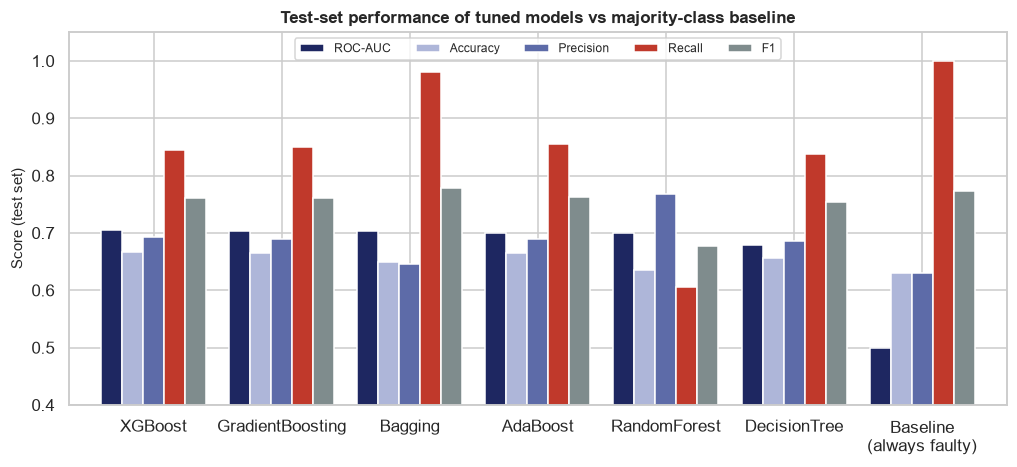

In [36]:
# bar chart of test scores for each model vs the baseline
fig, ax = plt.subplots(figsize=(11, 4.4))
m = res.set_index("model")[["test_roc_auc", "test_accuracy", "test_precision", "test_recall", "test_f1"]]
m.index = [i.replace("Baseline (always faulty)", "Baseline\n(always faulty)") for i in m.index]
m.columns = ["ROC-AUC", "Accuracy", "Precision", "Recall", "F1"]
m.plot(kind="bar", ax=ax, color=[NAVY, "#AEB6D9", "#5D6BA8", RED, GREY], width=0.82, edgecolor="white")
ax.set_ylim(0.4, 1.05); ax.set_ylabel("Score (test set)"); ax.set_xlabel("")
ax.set_title("Test-set performance of tuned models vs majority-class baseline"); ax.legend(ncol=5, fontsize=8, loc="upper center")
plt.xticks(rotation=0); save(fig, "fig12_model_comparison"); plt.show()

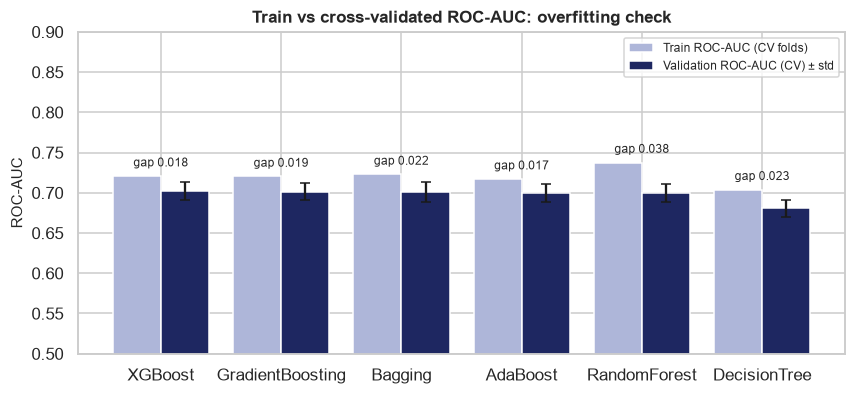

In [37]:
# train vs cv roc_auc - checking for overfitting
r6 = res[res.model != "Baseline (always faulty)"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(r6))
ax.bar(x - 0.2, r6["train_roc_auc"], 0.4, color="#AEB6D9", label="Train ROC-AUC (CV folds)")
ax.bar(x + 0.2, r6["cv_roc_auc"], 0.4, yerr=r6["cv_roc_auc_std"], color=NAVY, label="Validation ROC-AUC (CV) ± std", capsize=3)
for i, (t, v) in enumerate(zip(r6["train_roc_auc"], r6["cv_roc_auc"])):
    ax.text(i, max(t, v) + 0.012, f"gap {t-v:.3f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(r6["model"]); ax.set_ylim(0.5, 0.9); ax.set_ylabel("ROC-AUC")
ax.set_title("Train vs cross-validated ROC-AUC: overfitting check"); ax.legend(fontsize=8, loc="upper right")
save(fig, "fig13_overfit_check"); plt.show()

### 4.8 Looking closer at the best model

In [38]:
# load the saved best model and check it on the test set
import joblib
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
meta = json.load(open("models/best_model_metadata.json"))
best = joblib.load("models/best_model.joblib")
X_te, y_te = test.drop(columns="engine_condition"), test["engine_condition"]
pred = best.predict(X_te)
proba = best.predict_proba(X_te)[:, 1]
print("Best model:", meta["best_model"])
print(json.dumps(meta["best_params"], indent=2))
print(classification_report(y_te, pred, target_names=["Normal (0)", "Needs maintenance (1)"], digits=4))

Best model: XGBoost
{
  "colsample_bytree": 0.759395,
  "gamma": 3.515095,
  "learning_rate": 0.034445,
  "max_depth": 2,
  "min_child_weight": 12,
  "n_estimators": 394,
  "reg_lambda": 0.987409,
  "subsample": 0.720351
}
                       precision    recall  f1-score   support

           Normal (0)     0.5782    0.3636    0.4464      1444
Needs maintenance (1)     0.6936    0.8445    0.7616      2463

             accuracy                         0.6668      3907
            macro avg     0.6359    0.6040    0.6040      3907
         weighted avg     0.6509    0.6668    0.6451      3907



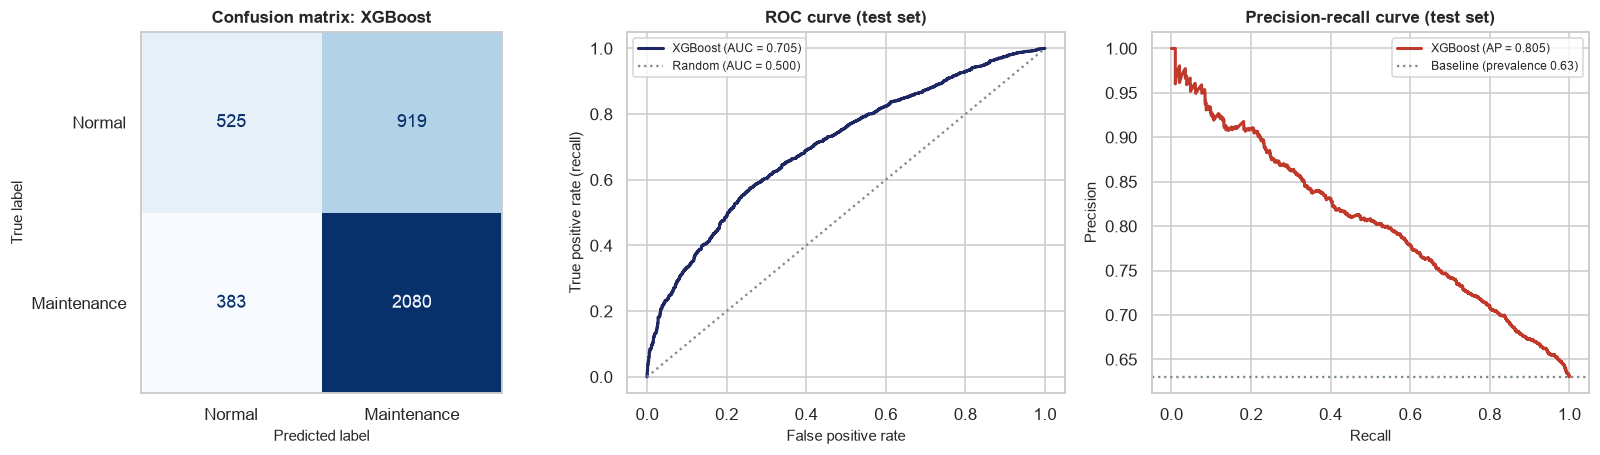

In [39]:
# confusion matrix, ROC curve and precision-recall curve
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["Normal", "Maintenance"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title(f"Confusion matrix: {meta['best_model']}"); axes[0].grid(False)
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
fpr, tpr, _ = roc_curve(y_te, proba)
axes[1].plot(fpr, tpr, color=NAVY, lw=2, label=f"{meta['best_model']} (AUC = {roc_auc_score(y_te, proba):.3f})")
axes[1].plot([0, 1], [0, 1], ls=":", color=GREY, label="Random (AUC = 0.500)")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("ROC curve (test set)"); axes[1].legend(fontsize=8)
prec, rec, _ = precision_recall_curve(y_te, proba)
axes[2].plot(rec, prec, color=RED, lw=2, label=f"{meta['best_model']} (AP = {average_precision_score(y_te, proba):.3f})")
axes[2].axhline(y_te.mean(), ls=":", color=GREY, label="Baseline (prevalence 0.63)")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].legend(fontsize=8)
axes[2].set_title("Precision-recall curve (test set)")
fig.tight_layout(); save(fig, "fig14_best_model_diagnostics"); plt.show()

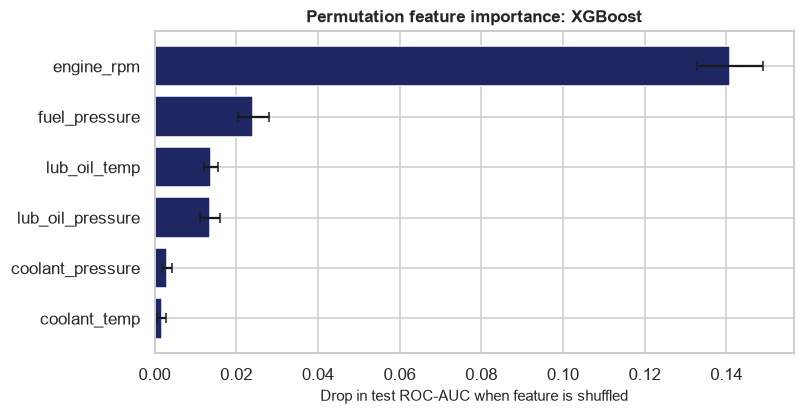

,auc_drop_when_shuffled,std,builtin_importance
engine_rpm,0.14,0.01,0.46
fuel_pressure,0.02,0.00,0.19
lub_oil_temp,0.01,0.00,0.13
lub_oil_pressure,0.01,0.00,0.09
coolant_pressure,0.00,0.00,0.07
coolant_temp,0.00,0.00,0.06


In [40]:
# which sensors matter most? shuffle one sensor at a time and see how much roc_auc drops
from sklearn.inspection import permutation_importance
feat = list(X_te.columns)
perm = permutation_importance(best, X_te, y_te, scoring="roc_auc", n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.DataFrame({"auc_drop_when_shuffled": perm.importances_mean, "std": perm.importances_std}, index=feat)
if hasattr(best, "feature_importances_"):
    imp["builtin_importance"] = best.feature_importances_
imp = imp.sort_values("auc_drop_when_shuffled")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(imp.index, imp["auc_drop_when_shuffled"], xerr=imp["std"], color=NAVY, capsize=3)
ax.set_xlabel("Drop in test ROC-AUC when feature is shuffled"); ax.set_title(f"Permutation feature importance: {meta['best_model']}")
save(fig, "fig15_feature_importance"); plt.show()
imp.sort_values("auc_drop_when_shuffled", ascending=False).round(4)

In [41]:
# looking at the mistakes - median sensor values for TP, TN, FP, FN
err = test.copy(); err["pred"] = pred
err["outcome"] = np.select([(err.pred==1)&(err.engine_condition==1), (err.pred==0)&(err.engine_condition==0),
                            (err.pred==1)&(err.engine_condition==0)], ["TP", "TN", "FP"], "FN")
pd.concat([err.groupby("outcome")[feat].median(), err["outcome"].value_counts().rename("count")], axis=1).round(2)

,engine_rpm,lub_oil_pressure,fuel_pressure,coolant_pressure,lub_oil_temp,coolant_temp,count
outcome,,,,,,,
FN,993.00,2.82,5.07,2.21,77.52,79.62,383
FP,740.00,3.16,6.52,2.19,76.70,78.49,919
TN,"1,029.00",2.83,4.87,2.23,77.65,79.47,525
TP,641.00,3.28,6.68,2.09,76.49,77.88,2080


In [42]:
# what happens if we change the 0.5 cut-off?
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
th = pd.DataFrame([{"threshold": round(t, 2), "precision": precision_score(y_te, proba>=t), "recall": recall_score(y_te, proba>=t),
                    "f1": f1_score(y_te, proba>=t), "accuracy": accuracy_score(y_te, proba>=t),
                    "engines_flagged_pct": 100*(proba>=t).mean()} for t in np.arange(0.40, 0.81, 0.05)])
th.round(4)

,threshold,precision,recall,f1,accuracy,engines_flagged_pct
0,0.40,0.66,0.95,0.78,0.65,91.25
1,0.45,0.67,0.90,0.77,0.66,84.80
2,0.50,0.69,0.84,0.76,0.67,76.76
3,0.55,0.72,0.77,0.74,0.67,67.67
4,0.60,0.75,0.69,0.71,0.66,57.90
5,0.65,0.78,0.59,0.67,0.64,47.25
6,0.70,0.81,0.48,0.61,0.60,37.70
7,0.75,0.84,0.37,0.51,0.56,27.69
8,0.80,0.87,0.27,0.41,0.51,19.22


In [43]:
# final check - files saved in models/
print("Files saved for the pipeline to commit:")
for f in sorted(os.listdir("models")):
    print(f"  models/{f}  ({os.path.getsize('models/'+f)/1024:,.1f} KB)")
print(json.dumps(meta, indent=2))

Files saved for the pipeline to commit:
  models/best_model.joblib  (343.3 KB)
  models/best_model_metadata.json  (0.8 KB)
  models/experiment_results.csv  (2.6 KB)
{
  "best_model": "XGBoost",
  "selection_metric": "cv_roc_auc (5-fold, training set)",
  "features": [
    "engine_rpm",
    "lub_oil_pressure",
    "fuel_pressure",
    "coolant_pressure",
    "lub_oil_temp",
    "coolant_temp"
  ],
  "target": "engine_condition",
  "decision_threshold": 0.5,
  "best_params": {
    "colsample_bytree": 0.759395,
    "gamma": 3.515095,
    "learning_rate": 0.034445,
    "max_depth": 2,
    "min_child_weight": 12,
    "n_estimators": 394,
    "reg_lambda": 0.987409,
    "subsample": 0.720351
  },
  "cv_roc_auc": 0.7023,
  "test_metrics": {
    "accuracy": 0.6668,
    "precision": 0.6936,
    "recall": 0.8445,
    "f1": 0.7616,
    "roc_auc": 0.7048
  },
  "mlflow_experiment": "engine-predictive-maintenance",
  "mlflow_run_id": "d54048b8911640eba5427a128ab5e4ba"
}


### 4.9 Summary so far
* All 6 models are very close (ROC-AUC around 0.70), which makes sense since the classes overlap a lot. The data is the limit here, not the model.
* XGBoost was the best on CV ROC-AUC and is saved in `models/best_model.joblib` with its metadata.
* MLflow has all the runs - 120 child runs (6 models x 20 tries), 6 parent runs and 1 baseline run.
* To do: choose a better cut-off using the cost of a missed fault vs a false alarm.